# Multiple Regression

Let's grab a small little data set of Blue Book car values:

In [1]:
import pandas as pd

df = pd.read_excel('cars.xls')


                     Mileage         Price
Mileage                                   
(0, 10000]       5588.629630  24096.714451
(10000, 20000]  15898.496183  21955.979607
(20000, 30000]  24114.407104  20278.606252
(30000, 40000]  33610.338710  19463.670267


<Axes: xlabel='Mileage'>

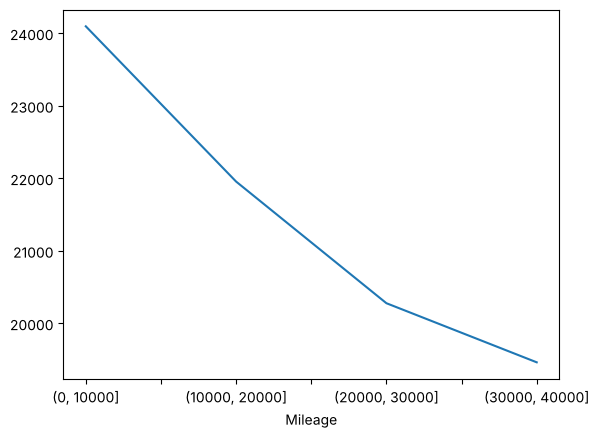

In [2]:
%matplotlib inline
import numpy as np
df1=df[['Mileage','Price']]
bins =  np.arange(0,50000,10000)
groups = df1.groupby(pd.cut(df1['Mileage'],bins)).mean()
print(groups.head())
groups['Price'].plot.line()


We can use pandas to split up this matrix into the feature vectors we're interested in, and the value we're trying to predict.

Let's scale our feature data into the same range so we can easily compare the coefficients we end up with.

In [3]:
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
scale = StandardScaler()

X = df[['Mileage', 'Cylinder', 'Doors']]
y = df['Price']

# standardisation
X[['Mileage', 'Cylinder', 'Doors']] = scale.fit_transform(X[['Mileage', 'Cylinder', 'Doors']].values)

print (X)

#Ordinary Least Squares to create the model
est = sm.OLS(y, X).fit()

est.summary()

      Mileage  Cylinder     Doors
0   -1.417485   0.52741  0.556279
1   -1.305902   0.52741  0.556279
2   -0.810128   0.52741  0.556279
3   -0.426058   0.52741  0.556279
4    0.000008   0.52741  0.556279
..        ...       ...       ...
799 -0.439853   0.52741  0.556279
800 -0.089966   0.52741  0.556279
801  0.079605   0.52741  0.556279
802  0.750446   0.52741  0.556279
803  1.932565   0.52741  0.556279

[804 rows x 3 columns]


<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                  Price   R-squared (uncentered):                   0.064
Model:                            OLS   Adj. R-squared (uncentered):              0.060
Method:                 Least Squares   F-statistic:                              18.11
Date:                Mon, 26 Oct 2026   Prob (F-statistic):                    2.23e-11
Time:                        20:54:51   Log-Likelihood:                         -9207.1
No. Observations:                 804   AIC:                                  1.842e+04
Df Residuals:                     801   BIC:                                  1.843e+04
Df Model:                           3                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Mileage    -1272.3412    804.623     -1.581      0.114   -2851.759     307.077
Cylinder    5587.4472    804.509      6.945      0.000    4008.252    7166.642
Doors      -1404.5513    804.275     -1.746      0.081   -2983.288     174.185
==============================================================================
Omnibus:                      157.913   Durbin-Watson:                   0.008
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              257.529
Skew:                           1.278   Prob(JB):                     1.20e-56
Kurtosis:                       4.074   Cond. No.                         1.03
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

**Explication du code**

- On lit le fichier `cars.xls` avec pandas. On regroupe ensuite les voitures par tranche de kilométrage (`pd.cut`) et on affiche le prix moyen : le prix baisse quand le kilométrage augmente (de 24 100 pour moins de 10 000 miles à 19 460 pour 30 000 à 40 000 miles).
- On prend les variables explicatives `Mileage`, `Cylinder` et `Doors`, et la cible `Price`. Les variables sont standardisées avec `StandardScaler` (moyenne 0, écart-type 1) pour pouvoir comparer les coefficients entre eux.
- `sm.OLS(y, X).fit()` ajuste une régression linéaire multiple par moindres carrés ordinaires, et `summary()` affiche les résultats.

**Lecture des résultats**

- `coef` : l'effet sur le prix d'une augmentation d'un écart-type de la variable (les autres restant constantes). `std err` : l'incertitude sur ce coefficient. `t` = coef / std err et `P>|t|` : la p-value du test que le coefficient est nul ; si elle est inférieure à 0.05 le coefficient est significatif. `[0.025 0.975]` : intervalle de confiance à 95%.
- `R-squared` = 0.064 et `F-statistic` = 18.11 avec `Prob (F-statistic)` = 2.2e-11 : le modèle est globalement significatif, mais le R² est très faible. Cela vient du fait qu'il n'y a **pas de constante** dans le modèle (la note [1] en bas de la sortie dit que le R² est "uncentered"), donc ce R² n'est pas comparable à un R² normal. En ajoutant une constante avec `sm.add_constant` on obtient un R² de 0.36.

**Comparaison des coefficients**

- `Cylinder` a le coefficient le plus grand (+5587) et une p-value de 0.000 : c'est la variable qui influence le plus le prix, plus de cylindres veut dire une voiture plus chère.
- `Mileage` a un coefficient négatif (-1272) : plus le kilométrage est élevé, plus le prix baisse. Dans ce modèle sans constante la p-value est 0.114, donc non significatif, mais il le devient avec une constante (t = -4.55) car l'erreur standard est plus petite.
- `Doors` a un coefficient négatif (-1404, p = 0.081 sans constante), donc le nombre de portes n'a pas l'effet attendu : dans les données, les voitures à 2 portes sont plus chères en moyenne (23 807 contre 20 581), car ce sont souvent des coupés ou des cabriolets plus puissants.
- Comme les variables sont standardisées, on peut les comparer directement : Cylinder > Doors ≈ Mileage en valeur absolue.

**Remarque sur la prédiction** : pour 45 000 miles, 8 cylindres et 4 portes, le modèle prédit seulement 6 315, ce qui est beaucoup trop bas par rapport aux prix du jeu de données (environ 20 000). C'est à cause de l'absence de constante dans le modèle (l'ordonnée à l'origine manque).


    
Now, lets find out if the number of doors is important in predicting car prices:

In [4]:
y.groupby(df.Doors).mean()

Doors
2    23807.135520
4    20580.670749
Name: Price, dtype: float64


How would you use the learned model to make an actual prediction? Start by scaling your multiple feature variables into the same scale used to train the model, then just call est.predict() on the scaled features:

In [5]:
#Prediction for a car with 45000 Mileage, 8 cylinders and 4 doors
scaled = scale.transform([[45000, 8, 4]])
print(scaled)
predicted = est.predict(scaled)
print(predicted)

[[3.07256589 1.96971667 0.55627894]]
[6315.01330583]


## Activity

- Create a copy of the input data on your disk, and see if you can create a measurable influence of number of doors on price. 
- Look if there are Outliers in the dataset, if yes, do some data cleaning.
- Try adding 8 door cars into the set and see how it affects the results.

In [6]:
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler

# 1) copie des données sur le disque
df_copy = df.copy()
df_copy.to_csv('cars_copy.csv', index=False)
df_copy = pd.read_csv('cars_copy.csv')
print(df_copy.shape)

(804, 12)


In [7]:
# Dans les données d'origine, le nombre de portes n'a pas d'influence significative.
# On crée une influence sur la copie : chaque porte ajoute 5000 $ au prix
df_copy['Price'] = df_copy['Price'] + 5000 * df_copy['Doors']

print(df_copy.groupby('Doors')['Price'].mean())

sc = StandardScaler()
Xc = pd.DataFrame(sc.fit_transform(df_copy[['Mileage', 'Cylinder', 'Doors']]), columns=['Mileage', 'Cylinder', 'Doors'])
Xc = sm.add_constant(Xc)
est_c = sm.OLS(df_copy['Price'].values, Xc).fit()
print(est_c.summary().tables[1])

Doors
2    33807.135520
4    40580.670749
Name: Price, dtype: float64
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       3.898e+04    279.405    139.510      0.000    3.84e+04    3.95e+04
Mileage    -1272.3412    279.567     -4.551      0.000   -1821.112    -723.571
Cylinder    5587.4472    279.527     19.989      0.000    5038.754    6136.140
Doors       2843.6485    279.446     10.176      0.000    2295.115    3392.182


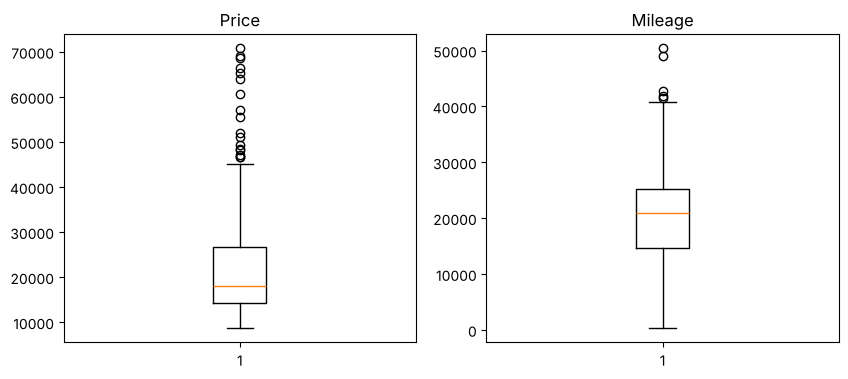

Price : nombre d'outliers = 17
Mileage : nombre d'outliers = 5


In [8]:
# 2) Recherche des outliers (boîtes à moustaches + règle de l'IQR) sur les données d'origine
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].boxplot(df['Price'])
axes[0].set_title('Price')
axes[1].boxplot(df['Mileage'])
axes[1].set_title('Mileage')
plt.show()

def iqr_mask(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return (s >= q1 - 1.5 * iqr) & (s <= q3 + 1.5 * iqr)

for col in ['Price', 'Mileage']:
    print(col, ": nombre d'outliers =", (~iqr_mask(df[col])).sum())

In [9]:
# nettoyage : on garde seulement les lignes sans outlier sur Price et Mileage
df_clean = df[iqr_mask(df['Price']) & iqr_mask(df['Mileage'])].copy()
print("avant :", df.shape, " après :", df_clean.shape)

def fit_model(data):
    sc = StandardScaler()
    X_ = pd.DataFrame(sc.fit_transform(data[['Mileage', 'Cylinder', 'Doors']]), columns=['Mileage', 'Cylinder', 'Doors'])
    X_ = sm.add_constant(X_)
    return sm.OLS(data['Price'].values, X_).fit()

m_avant = fit_model(df)
m_apres = fit_model(df_clean)
print("R² avant nettoyage :", round(m_avant.rsquared, 4))
print("R² après nettoyage :", round(m_apres.rsquared, 4))
print()
print("Coefficients avant :", m_avant.params.round(1).tolist())
print("Coefficients après :", m_apres.params.round(1).tolist())

avant : (804, 12)  après : (783, 12)
R² avant nettoyage : 0.36
R² après nettoyage : 0.2883

Coefficients avant : [21343.1, -1272.3, 5587.4, -1404.6]
Coefficients après : [20553.7, -967.9, 4388.3, -647.5]


In [10]:
# 3) On ajoute des voitures à 8 portes (données inventées, prix élevés)
np.random.seed(0)
extra = df.sample(20, random_state=0).copy()
extra['Doors'] = 8
extra['Price'] = extra['Price'] * 1.8       # on suppose qu'elles sont plus chères
df_8 = pd.concat([df, extra], ignore_index=True)

print(df_8['Doors'].value_counts())

m8 = fit_model(df_8)
print("R² sans 8 portes :", round(m_avant.rsquared, 4), "  avec 8 portes :", round(m8.rsquared, 4))
print()
print("Coef. Doors sans 8 portes :", round(m_avant.params['Doors'], 1), " p-value :", round(m_avant.pvalues['Doors'], 4))
print("Coef. Doors avec 8 portes :", round(m8.params['Doors'], 1), " p-value :", round(m8.pvalues['Doors'], 4))

Doors
4    614
2    190
8     20
Name: count, dtype: int64
R² sans 8 portes : 0.36   avec 8 portes : 0.303

Coef. Doors sans 8 portes : -1404.6  p-value : 0.0
Coef. Doors avec 8 portes : 1170.9  p-value : 0.0003


**Observations :**

- *Influence du nombre de portes* : sur la copie où on ajoute 5000 par porte, la différence de prix moyen entre 4 portes et 2 portes devient de plus de 6 700 (au lieu de -3 200 dans les données d'origine), et dans la régression (avec constante) le coefficient de `Doors` passe de -1405 à +2844 avec une p-value de 0.000. Donc on a bien créé une influence mesurable du nombre de portes sur le prix. (Le coefficient n'est pas égal à +3595 = -1405 + 5000 parce que, dans les données, Doors est standardisé : on ajoute 5000 par porte, ce qui fait 5000 × l'écart-type des portes, soit environ 4250 par unité standardisée. Mais comme l'effet d'origine était négatif, le total est +2844.)
- *Outliers* : les boîtes à moustaches montrent des outliers sur `Price` (17 voitures, surtout des voitures chères) et sur `Mileage` (5 voitures). Après suppression (règle de 1.5 × IQR), il reste 783 lignes. Le R² passe de 0.36 à 0.288 et les coefficients diminuent en valeur absolue (Cylinder de 5587 à 4388). Les outliers sont des voitures de luxe avec beaucoup de cylindres qui renforçaient la relation, donc le modèle nettoyé explique moins de variance, mais il est moins influencé par ces cas extrêmes.
- *Voitures à 8 portes* : on a ajouté 20 voitures inventées à 8 portes avec un prix 1.8 fois plus élevé. Le R² baisse (0.36 → 0.30) et surtout le coefficient de `Doors` change de signe (de -1405 à +1171, p = 0.0003). Quelques points extrêmes suffisent à changer complètement la conclusion : ce sont des points à fort effet de levier. Ça montre aussi qu'il ne faut pas extrapoler à des valeurs qui n'existent pas dans les données réelles.